# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Bakery Sales Dataset](https://www.kaggle.com/datasets/sdcloud/historical-bakery-sales-dataset)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

/kaggle/input/datasets/sdcloud/historical-bakery-sales-dataset/bakery_sales_dataset_Copy.xlsx
/kaggle/input/datasets/sdcloud/historical-bakery-sales-dataset/bakery_sales_dataset.csv


## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('bakery_sales_dataset.csv')

# Preprocessing

## Frist five row

In [3]:
pd.set_option('display.max_columns', None)
df.head()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,Day_of_Week,Weekend,Hour,Time,Season,Festival,Weather,Temperature,Product,Category,Quantity,Unit_Price,Cost_Price,Discount_Percentage,Selling_Price,Total_Bill,Payment_Method,Promotion_Applied,Promotion_Type,Shelf_Life_Days,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
0,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,Sunday,Yes,8,8:47,Winter,New Year,Foggy,21.2,Pastry,Pastry & Sweet,6,62.49,29.72,14.7,53.30,319.80,Cash,Yes,Festival,3,Refrigerated,Very High,ST02,8,6,2,2,25.0,141.48,4
1,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,Sunday,Yes,8,8:47,Winter,New Year,Foggy,21.2,Biscuit,Indian Bakery,3,30.14,12.63,13.9,25.95,77.85,Cash,Yes,Festival,64,Dry Storage,Low,ST02,4,3,1,1,25.0,39.96,4
2,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,Sunday,Yes,15,15:14,Winter,New Year,Foggy,21.2,Chocolate Cake,Cakes,1,425.49,256.56,15.3,360.39,360.39,UPI,Yes,Festival,3,Refrigerated,Very High,ST03,3,2,1,1,33.3,103.83,4
3,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,Sunday,Yes,15,15:14,Winter,New Year,Foggy,21.2,Nankhatai,Indian Bakery,7,30.29,13.18,18.9,24.57,171.99,UPI,Yes,Festival,23,Dry Storage,Low,ST03,13,10,3,2,23.1,79.73,4
4,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,Sunday,Yes,15,15:14,Winter,New Year,Foggy,21.2,Paav,Bread & Daily,3,7.94,3.64,11.9,7.00,21.00,UPI,Yes,Festival,1,Room Temperature,Very High,ST03,4,3,1,1,25.0,10.08,4


## last Five row

In [4]:
df.tail()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,Day_of_Week,Weekend,Hour,Time,Season,Festival,Weather,Temperature,Product,Category,Quantity,Unit_Price,Cost_Price,Discount_Percentage,Selling_Price,Total_Bill,Payment_Method,Promotion_Applied,Promotion_Type,Shelf_Life_Days,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
19316,ORD06574,CUST0206,16,Female,Student,Yes,2024-12-31,2024,12,31,Tuesday,No,19,19:00,Winter,NaN,Clear,20.7,White Cream Roll,Pastry & Sweet,1,35.13,16.28,0.0,35.13,35.13,Cash,No,NaN,2,Refrigerated,Very High,ST01,2,1,1,1,50.0,18.85,4
19317,ORD06575,CUST0017,16,Male,Student,Yes,2024-12-31,2024,12,31,Tuesday,No,14,14:04,Winter,NaN,Clear,20.7,Pineapple Cake,Cakes,1,400.89,234.80,0.0,400.89,400.89,UPI,No,NaN,2,Refrigerated,Very High,ST02,2,1,1,1,50.0,166.09,4
19318,ORD06575,CUST0017,16,Male,Student,Yes,2024-12-31,2024,12,31,Tuesday,No,14,14:04,Winter,NaN,Clear,20.7,Tea Cake,Cakes,1,154.73,85.55,0.0,154.73,154.73,UPI,No,NaN,4,Room Temperature,High,ST02,2,1,1,1,50.0,69.18,4
19319,ORD06576,CUST0219,31,Female,Young Professional,No,2024-12-31,2024,12,31,Tuesday,No,13,13:46,Winter,NaN,Clear,20.7,Puff,Savoury Bakery,5,25.50,12.53,0.0,25.50,127.50,Card,No,NaN,1,Room Temperature,Very High,ST01,6,5,1,1,16.7,64.85,3
19320,ORD06576,CUST0219,31,Female,Young Professional,No,2024-12-31,2024,12,31,Tuesday,No,13,13:46,Winter,NaN,Clear,20.7,Paneer,Dairy & Spreads,1,77.76,52.10,7.6,71.85,71.85,Card,No,NaN,2,Refrigerated,Very High,ST01,2,1,1,1,50.0,19.75,3


## Shape of our dataset

In [5]:
df.shape

(19321, 40)

## List out all columns

In [6]:
df.columns

Index(['Order_ID', 'Customer_ID', 'Customer_Age', 'Customer_Gender',
       'Customer_Segment', 'Loyalty_Member', 'Date', 'Year', 'Month', 'Day',
       'Day_of_Week', 'Weekend', 'Hour', 'Time', 'Season', 'Festival',
       'Weather', 'Temperature', 'Product', 'Category', 'Quantity',
       'Unit_Price', 'Cost_Price', 'Discount_Percentage', 'Selling_Price',
       'Total_Bill', 'Payment_Method', 'Promotion_Applied', 'Promotion_Type',
       'Shelf_Life_Days', 'Storage_Type', 'Perishability', 'Store_ID',
       'Units_Produced', 'Units_Sold', 'Unsold_Units', 'Stock_Available',
       'Waste_Pct', 'Profit', 'Customer_Rating'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

Order_ID                object
Customer_ID             object
Customer_Age             int64
Customer_Gender         object
Customer_Segment        object
Loyalty_Member          object
Date                    object
Year                     int64
Month                    int64
Day                      int64
Day_of_Week             object
Weekend                 object
Hour                     int64
Time                    object
Season                  object
Festival                object
Weather                 object
Temperature            float64
Product                 object
Category                object
Quantity                 int64
Unit_Price             float64
Cost_Price             float64
Discount_Percentage    float64
Selling_Price          float64
Total_Bill             float64
Payment_Method          object
Promotion_Applied       object
Promotion_Type          object
Shelf_Life_Days          int64
Storage_Type            object
Perishability           object
Store_ID

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  object 
 1   Customer_ID          19321 non-null  object 
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  object 
 4   Customer_Segment     19321 non-null  object 
 5   Loyalty_Member       19321 non-null  object 
 6   Date                 19321 non-null  object 
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  object 
 11  Weekend              19321 non-null  object 
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  object 
 14  Season               19321 non-null  object 
 15  Festival             3315 non-null  

## Check Null Value

In [9]:
df.isnull().sum()

Order_ID                   0
Customer_ID                0
Customer_Age               0
Customer_Gender            0
Customer_Segment           0
Loyalty_Member             0
Date                       0
Year                       0
Month                      0
Day                        0
Day_of_Week                0
Weekend                    0
Hour                       0
Time                       0
Season                     0
Festival               16006
Weather                    0
Temperature                0
Product                    0
Category                   0
Quantity                   0
Unit_Price                 0
Cost_Price                 0
Discount_Percentage        0
Selling_Price              0
Total_Bill                 0
Payment_Method             0
Promotion_Applied          0
Promotion_Type         13826
Shelf_Life_Days            0
Storage_Type               0
Perishability              0
Store_ID                   0
Units_Produced             0
Units_Sold    

## Drop Null Feachers

In [10]:
df.drop(columns=['Festival', 'Promotion_Type'], inplace=True)

## Check Dupicate Value

In [11]:
df.duplicated().sum()

np.int64(0)

## Summary

In [12]:
df.describe()

,Customer_Age,Year,Month,Day,Hour,Temperature,Quantity,Unit_Price,Cost_Price,Discount_Percentage,Selling_Price,Total_Bill,Shelf_Life_Days,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
count,19321.000000,19321.000000,19321.000000,19321.000000,19321.00000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000,19321.000000
mean,35.541846,2023.508100,6.559184,15.871901,12.86481,26.988127,2.226955,87.263624,49.275521,4.345541,83.372033,139.268467,61.117333,4.221469,3.046788,1.174680,1.131101,34.118715,59.196602,3.827700
std,13.733832,0.499947,3.478048,8.767930,3.94044,8.813511,1.782968,110.481951,65.969024,6.794384,105.762887,157.772593,103.611553,3.635227,3.038092,0.783283,0.752667,12.734206,65.238370,0.948831
min,16.000000,2023.000000,1.000000,1.000000,7.00000,8.100000,1.000000,7.600000,3.270000,0.000000,5.680000,13.120000,1.000000,2.000000,1.000000,1.000000,1.000000,4.200000,-0.550000,1.000000
25%,25.000000,2023.000000,4.000000,8.000000,9.00000,21.200000,1.000000,31.020000,16.900000,0.000000,30.400000,52.120000,3.000000,2.000000,1.000000,1.000000,1.000000,25.000000,20.690000,3.000000
50%,34.000000,2024.000000,7.000000,16.000000,12.00000,27.700000,2.000000,45.090000,23.640000,0.000000,42.660000,82.800000,5.000000,3.000000,2.000000,1.000000,1.000000,33.300000,36.760000,4.000000
75%,45.000000,2024.000000,10.000000,24.000000,17.00000,33.200000,3.000000,76.650000,52.640000,7.500000,72.030000,146.540000,82.000000,5.000000,4.000000,1.000000,1.000000,50.000000,65.920000,4.000000
max,73.000000,2024.000000,12.000000,31.000000,21.00000,44.900000,20.000000,472.420000,296.280000,30.000000,472.420000,1885.960000,729.000000,49.000000,37.000000,16.000000,20.000000,50.000000,767.600000,5.000000


# EDA

In [13]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

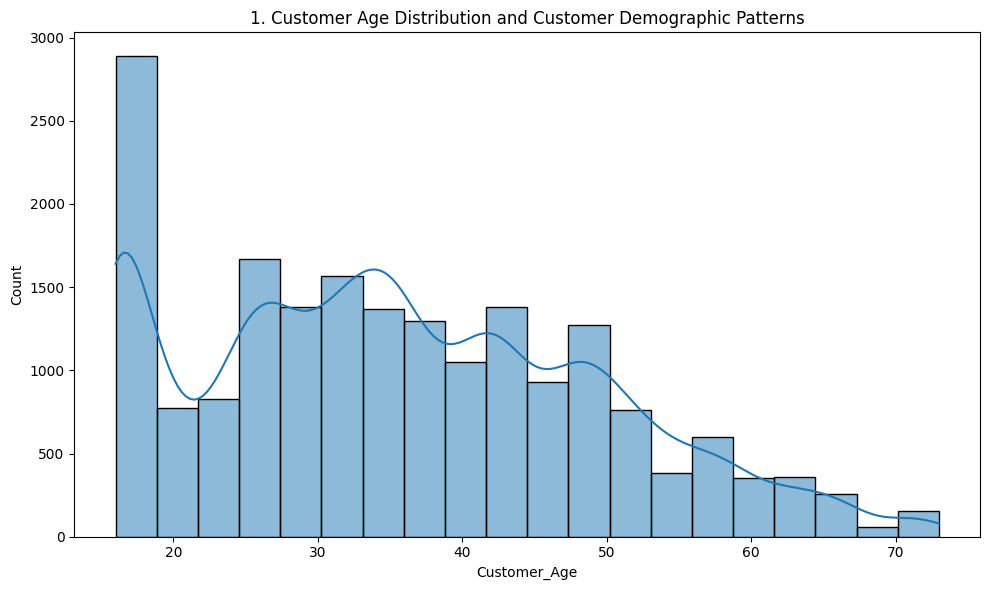

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='Customer_Age', bins=20, kde=True)
plt.title(f'{plot_no}. Customer Age Distribution and Customer Demographic Patterns')
show_fig()
plot_no += 1

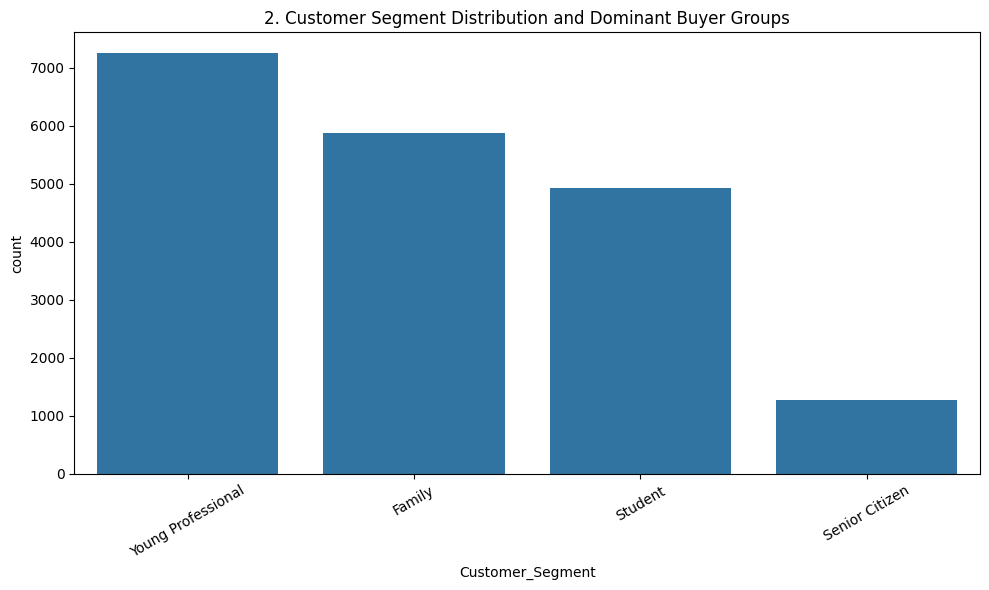

In [15]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='Customer_Segment', order=df['Customer_Segment'].value_counts().index)
plt.title(f'{plot_no}. Customer Segment Distribution and Dominant Buyer Groups')
plt.xticks(rotation=30)
show_fig()
plot_no += 1

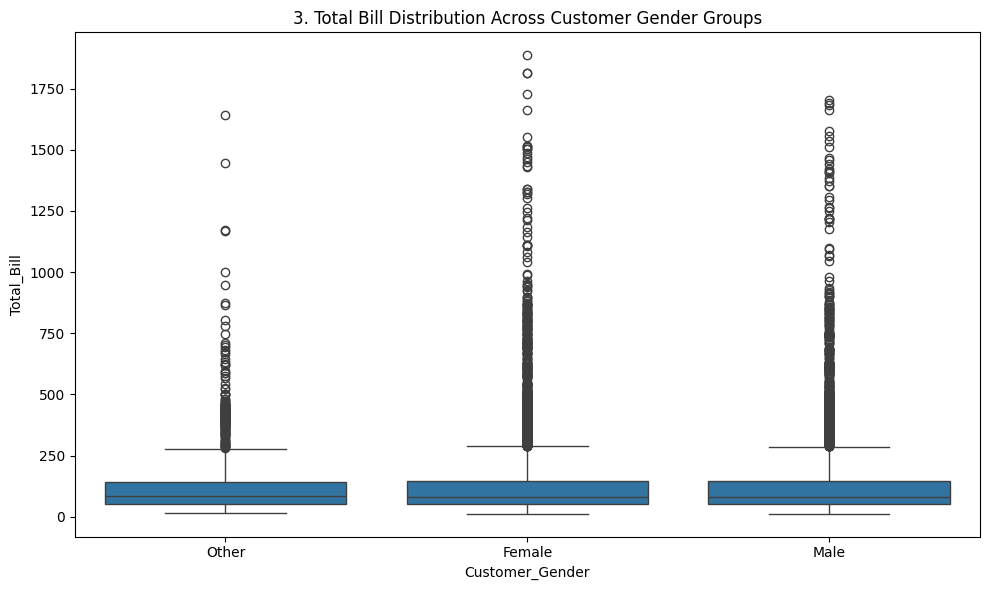

In [16]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Customer_Gender', y='Total_Bill')
plt.title(f'{plot_no}. Total Bill Distribution Across Customer Gender Groups')
show_fig()
plot_no += 1

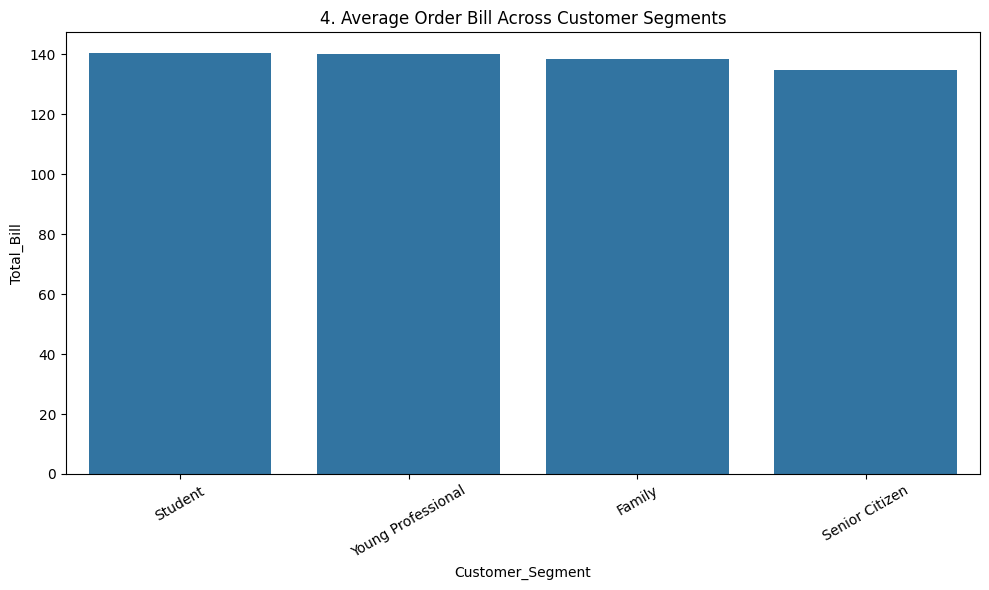

In [17]:
fig = plt.figure(figsize=(10,6))
segment_bill = df.groupby('Customer_Segment', observed=True)['Total_Bill'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=segment_bill, x='Customer_Segment', y='Total_Bill')
plt.title(f'{plot_no}. Average Order Bill Across Customer Segments')
plt.xticks(rotation=30)
show_fig()
plot_no += 1

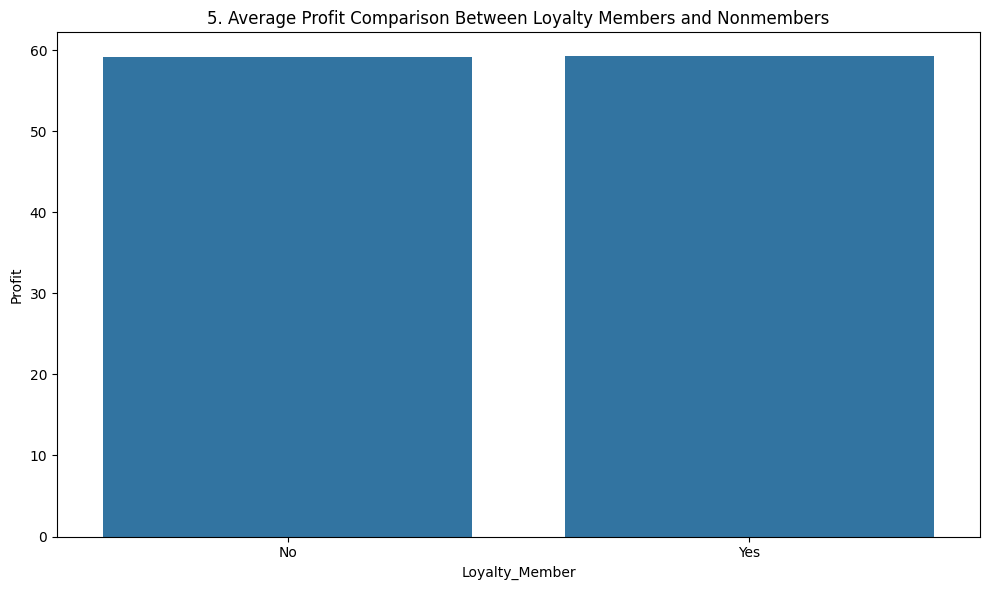

In [18]:
fig = plt.figure(figsize=(10,6))
loyalty_profit = df.groupby('Loyalty_Member', observed=True)['Profit'].mean().reset_index()
sns.barplot(data=loyalty_profit, x='Loyalty_Member', y='Profit')
plt.title(f'{plot_no}. Average Profit Comparison Between Loyalty Members and Nonmembers')
show_fig()
plot_no += 1

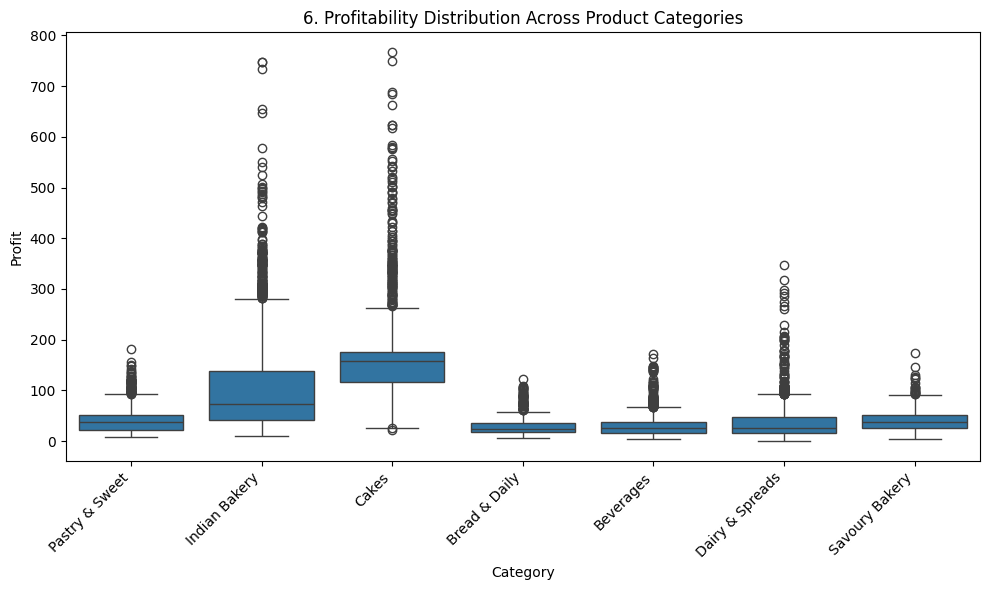

In [19]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='Category', y='Profit')
plt.title(f'{plot_no}. Profitability Distribution Across Product Categories')
plt.xticks(rotation=45, ha='right')
show_fig()

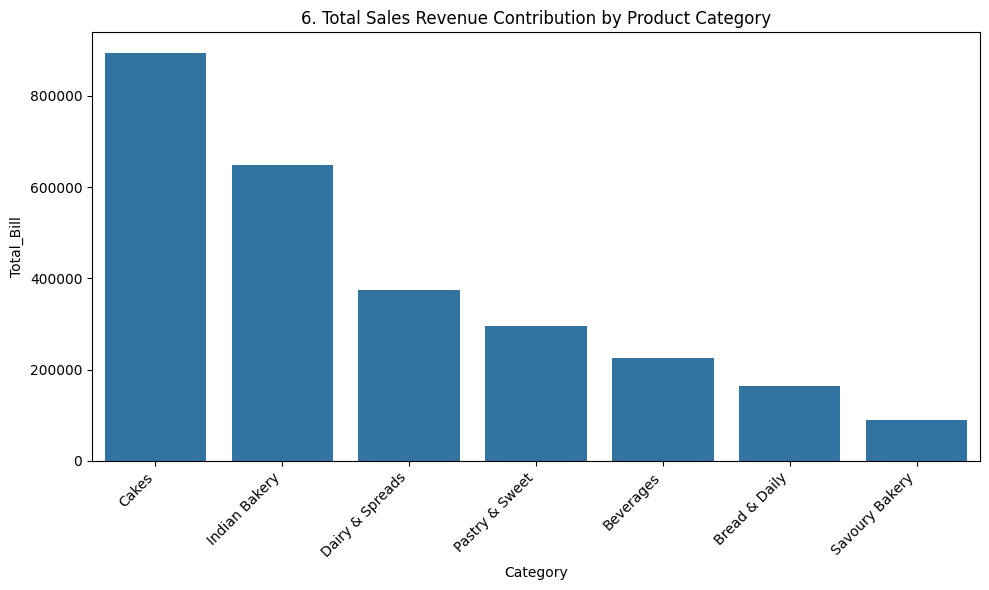

In [20]:
fig = plt.figure(figsize=(10,6))
category_sales = df.groupby('Category', observed=True)['Total_Bill'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=category_sales, x='Category', y='Total_Bill')
plt.title(f'{plot_no}. Total Sales Revenue Contribution by Product Category')
plt.xticks(rotation=45, ha='right')
show_fig()
plot_no += 1

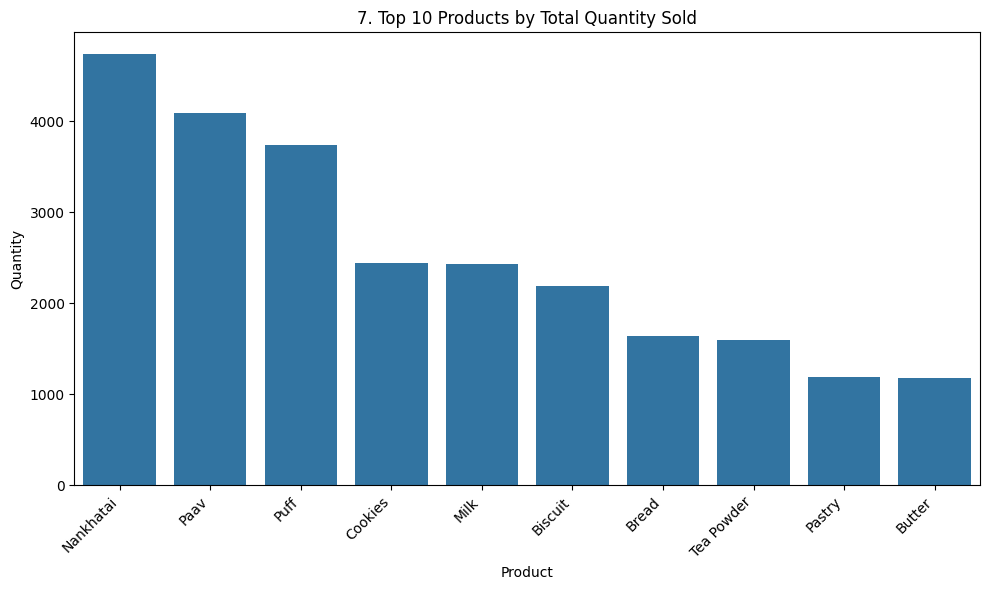

In [21]:
fig = plt.figure(figsize=(10,6))
top_products = df.groupby('Product', observed=True)['Quantity'].sum().nlargest(10).sort_values(ascending=False).reset_index()
sns.barplot(data=top_products, x='Product', y='Quantity')
plt.title(f'{plot_no}. Top 10 Products by Total Quantity Sold')
plt.xticks(rotation=45, ha='right')
show_fig()
plot_no += 1

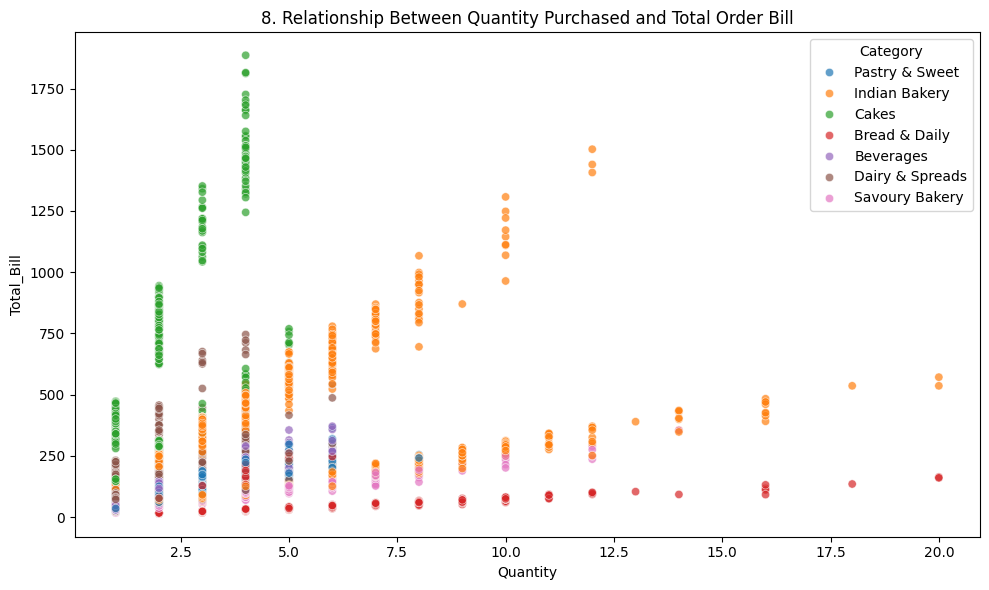

In [22]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Quantity', y='Total_Bill', hue='Category', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Quantity Purchased and Total Order Bill')
show_fig()
plot_no += 1

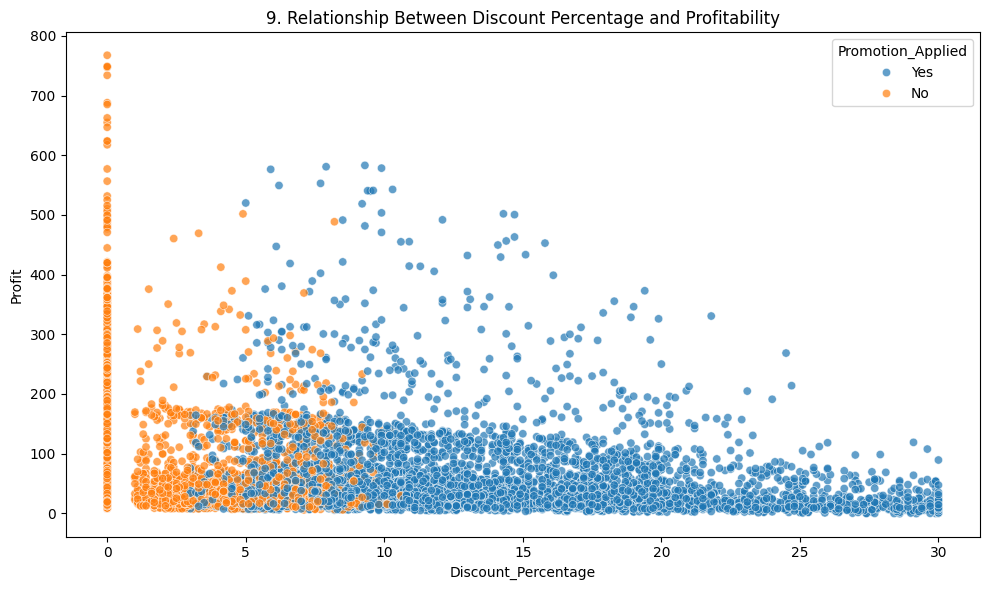

In [23]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Discount_Percentage', y='Profit', hue='Promotion_Applied', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Discount Percentage and Profitability')
show_fig()
plot_no += 1

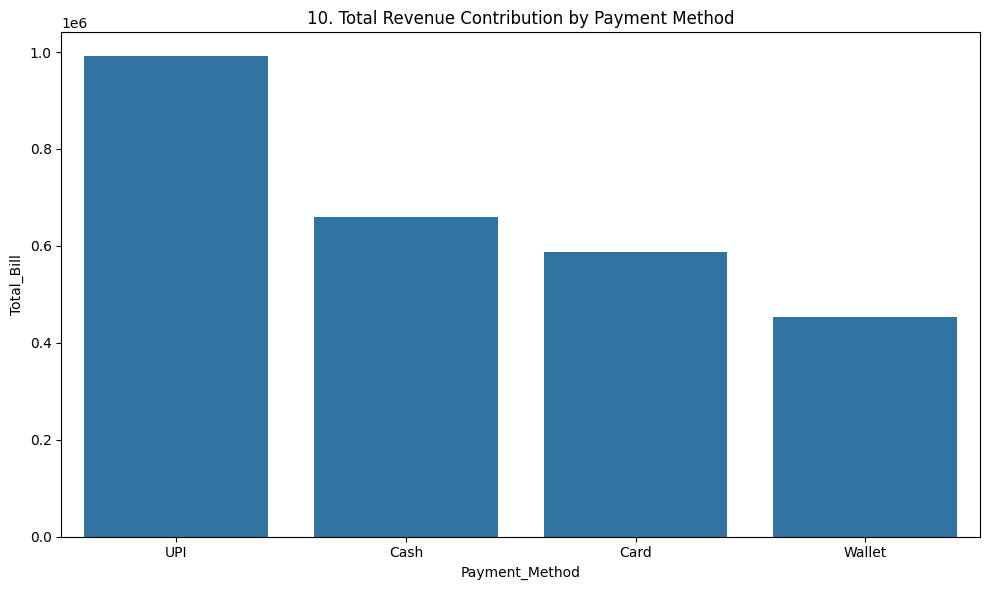

In [24]:
fig = plt.figure(figsize=(10,6))
payment_sales = df.groupby('Payment_Method', observed=True)['Total_Bill'].sum().sort_values(ascending=False).reset_index()
sns.barplot(data=payment_sales, x='Payment_Method', y='Total_Bill')
plt.title(f'{plot_no}. Total Revenue Contribution by Payment Method')
show_fig()
plot_no += 1

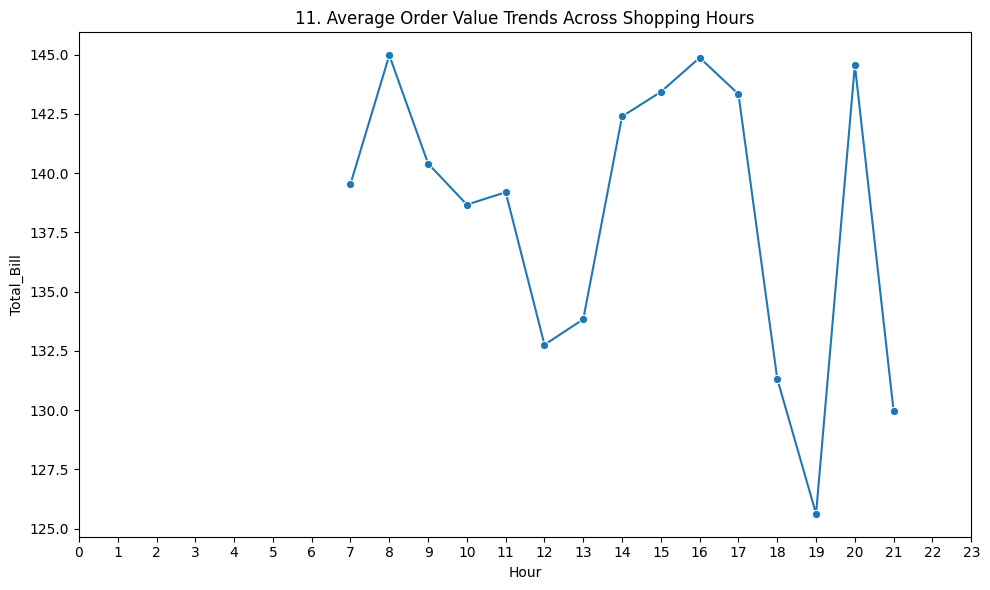

In [25]:
fig = plt.figure(figsize=(10,6))
hourly_sales = df.groupby('Hour', observed=True)['Total_Bill'].mean().reset_index()
sns.lineplot(data=hourly_sales, x='Hour', y='Total_Bill', marker='o')
plt.title(f'{plot_no}. Average Order Value Trends Across Shopping Hours')
plt.xticks(range(0,24))
show_fig()
plot_no += 1

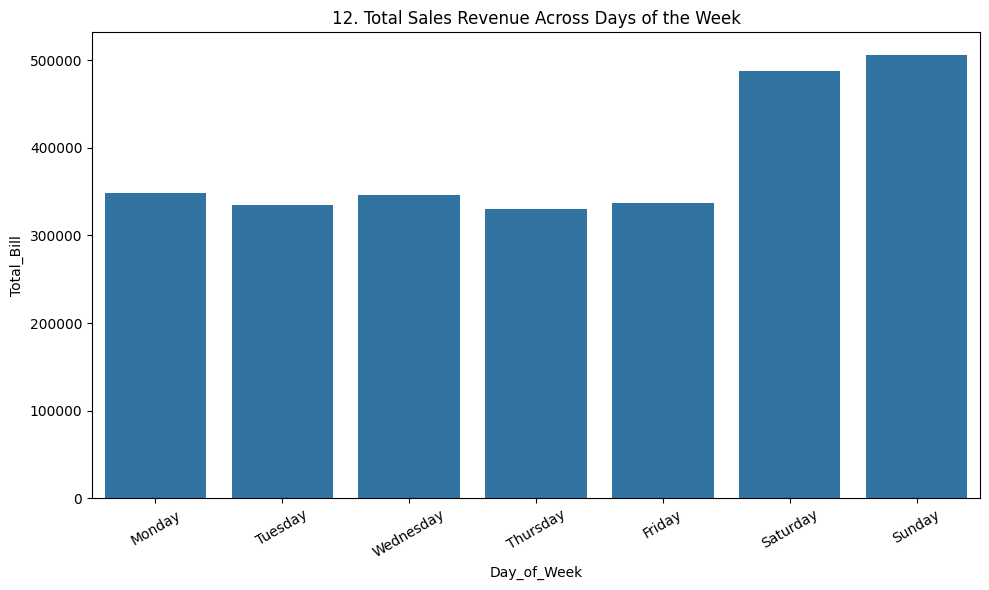

In [26]:
fig = plt.figure(figsize=(10,6))
daily_sales = df.groupby('Day_of_Week', observed=True)['Total_Bill'].sum().reset_index()
sns.barplot(data=daily_sales, x='Day_of_Week', y='Total_Bill', order=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
plt.title(f'{plot_no}. Total Sales Revenue Across Days of the Week')
plt.xticks(rotation=30)
show_fig()
plot_no += 1

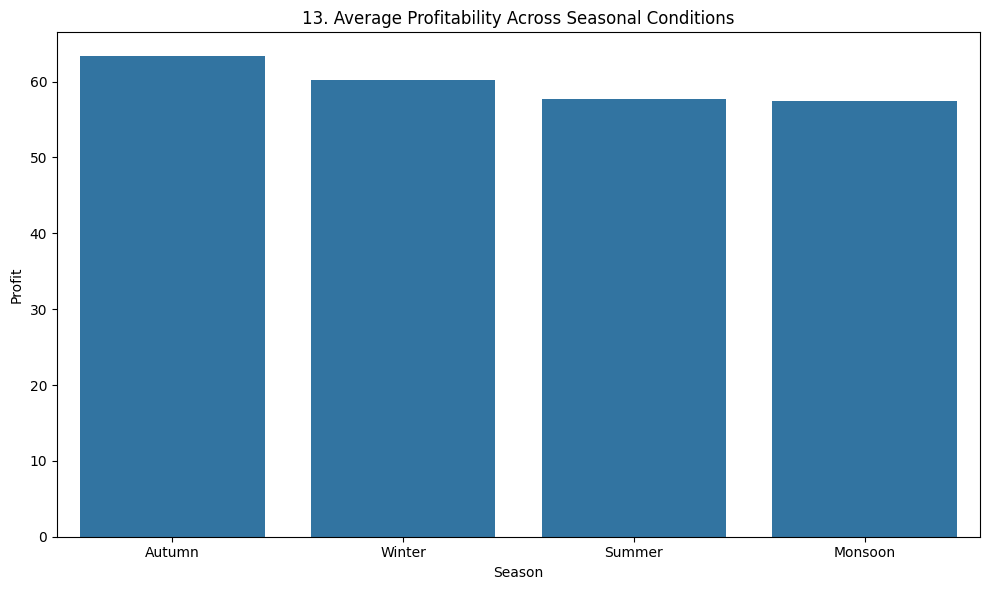

In [27]:
fig = plt.figure(figsize=(10,6))
seasonal_profit = df.groupby('Season', observed=True)['Profit'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=seasonal_profit, x='Season', y='Profit')
plt.title(f'{plot_no}. Average Profitability Across Seasonal Conditions')
show_fig()
plot_no += 1

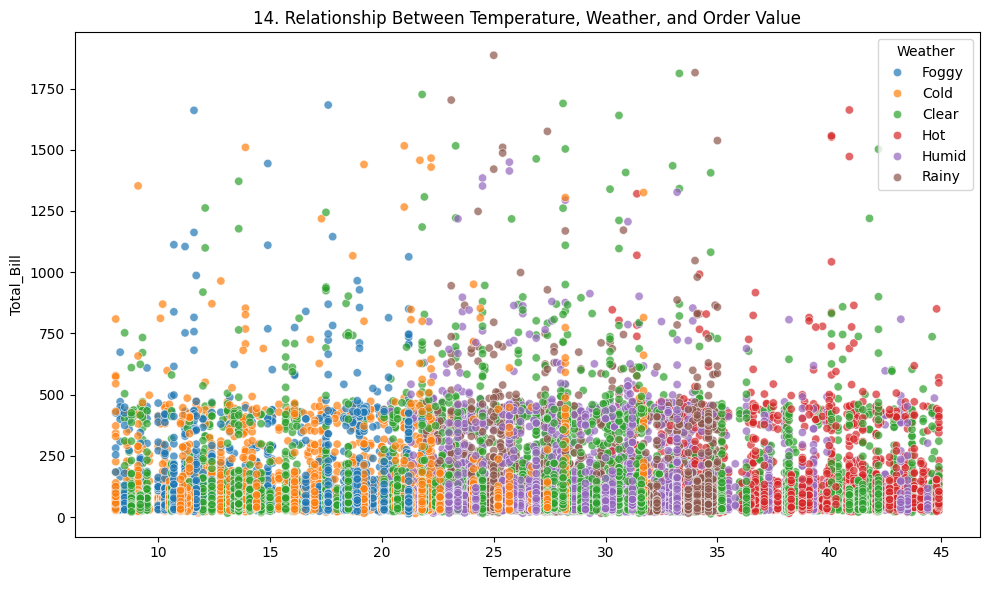

In [28]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Temperature', y='Total_Bill', hue='Weather', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Temperature, Weather, and Order Value')
show_fig()
plot_no += 1

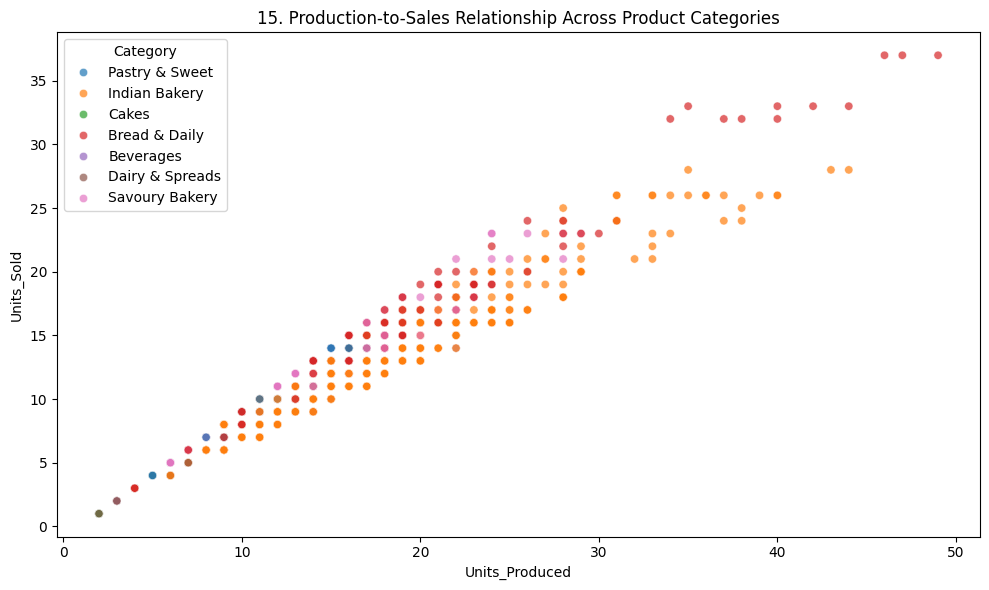

In [29]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Units_Produced', y='Units_Sold', hue='Category', alpha=0.7)
plt.title(f'{plot_no}. Production-to-Sales Relationship Across Product Categories')
show_fig()
plot_no += 1

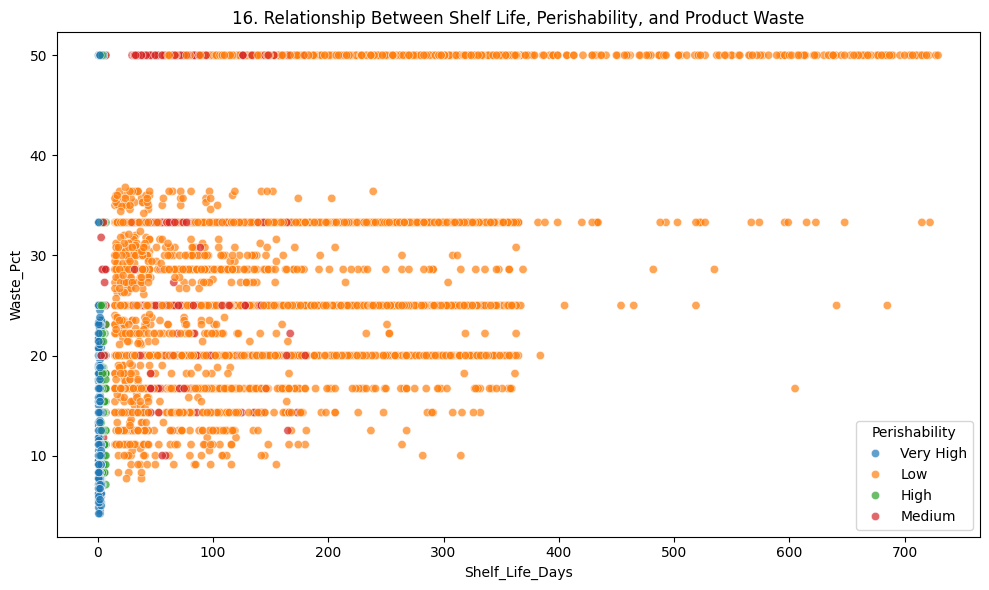

In [30]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='Shelf_Life_Days', y='Waste_Pct', hue='Perishability', alpha=0.7)
plt.title(f'{plot_no}. Relationship Between Shelf Life, Perishability, and Product Waste')
show_fig()
plot_no += 1

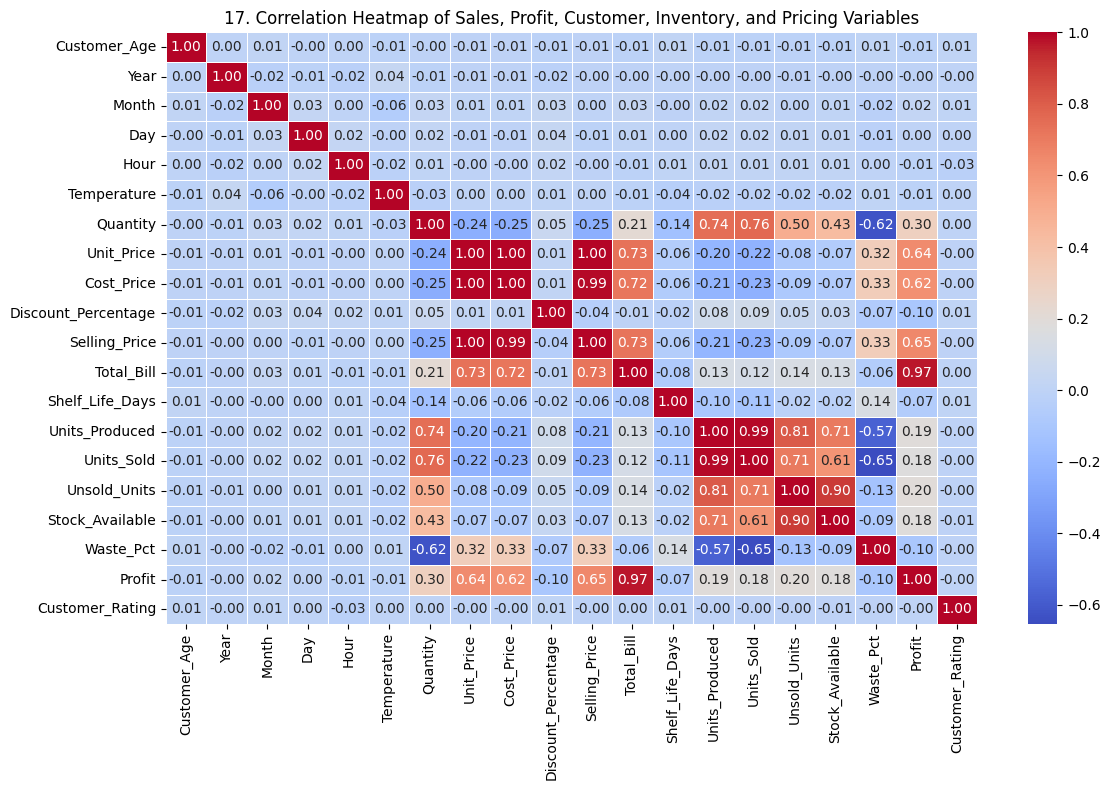

In [31]:
fig = plt.figure(figsize=(12,8))
corr = df.select_dtypes(include='number').corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Sales, Profit, Customer, Inventory, and Pricing Variables')
show_fig()
plot_no += 1

# Model Training

## Prepare the target and remove data leakage columns

In [32]:
target = 'Profit'
drop_cols = ['Profit', 'Order_ID', 'Customer_ID', 'Date', 'Time', 'Total_Bill']
X = df.drop(columns=[c for c in drop_cols if c in df.columns]).copy()
y = pd.to_numeric(df[target], errors='coerce')

## Remove rows with missing target values

In [33]:
valid = y.notna()
X, y = X.loc[valid], y.loc[valid]

## Identify numerical and categorical columns

In [34]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

## Build preprocessing pipelines

In [35]:
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

## Split data into training and testing sets

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Train a powerful Extra Trees regression model

In [37]:
model = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', ExtraTreesRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        max_features=0.9,
        random_state=42,
        n_jobs=-1
    ))
])
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Customer_Age', 'Year',
                                                   'Month', 'Day', 'Hour',
                                                   'Temperature', 'Quantity',
                                                   'Unit_Price', 'Cost_Price',
                                                   'Discount_Percentage',
                                                   'Selling_Price',
                                                   'Shelf_Life_Days',
                                                   'Units_Produced',
                                                   'Units_Sold', 'Unsold_Units',
                                                   'Stock_Available',
                                                   'W...
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['Customer_Gender',
                                                   'Customer_Segment',
                                                   'Loyalty_Member',
                                                   'Day_of_Week', 'Weekend',
                                                   'Season', 'Weather',
                                                   'Product', 'Category',
                                                   'Payment_Method',
                                                   'Promotion_Applied',
                                                   'Storage_Type',
                                                   'Perishability',
                                                   'Store_ID'])])),
                ('regressor',
                 ExtraTreesRegressor(max_features=0.9, min_samples_leaf=2,
                                     n_estimators=200, n_jobs=-1,
                                     random_state=42))])

## Generate predictions and evaluate the model

In [38]:
y_pred = model.predict(X_test)
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Absolute Error: {mean_absolute_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

R² Score: 0.9873
Mean Absolute Error: 1.9900
Root Mean Squared Error: 7.2528


## Plot actual versus predicted profit

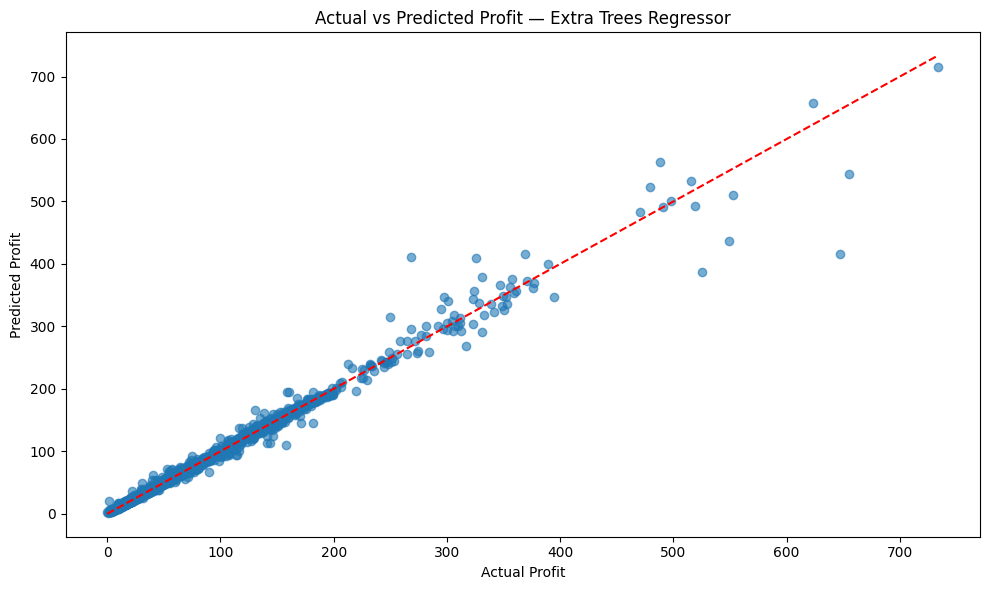

In [39]:
fig = plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--')
plt.xlabel('Actual Profit')
plt.ylabel('Predicted Profit')
plt.title('Actual vs Predicted Profit — Extra Trees Regressor')
show_fig()